# SAIDS 521 Assignment 3

## Introduction

**Pre-Dashboard Creation:**

At the time I'm completing this assingment, it is mid-November and my fantasy football team has already lost hope for the year. Given that, I thought it would be fun to explore some trends in historical fantasy football performances to help me prepare better for next season. I have some hunches on trends I want to capitalize on next season, so we'll be checking if they have any statistical validity.

**Post-Dashboard Creation:**

Now that I've created my dashboard, I have serveral takeaways that I think will help my fantasy football team next year. Trends, such as the lack of importance of the quarterback position, became increasingly clear as I was playing with my vizualizaitons. This trend along with how touchdown dependent certian positions are and which positions are more scarce/abundant arose and were answered during the creation of my dashboard.

Questions I had such as the effect of weather on player performance were answered as well, but not in the way I thought. I thought that colder weather would help runningbacks disproprtionatly, but it turns out that it brings all positions closer to the mean. 

I am confident that I will find out even more diving through the reactive capabilities of the dashboard, which I believe speaks for it's merit overall.

**Dashboard Link:**

https://saids-521-app-apdsay3gdmhyahqrrum2te.streamlit.app/

**Dashboard Image:**

![Dashboard Screenshot](images/dashboard.png)

## Libraries

When choosing a vizualization library, I wanted to choose one that is well known. I wanted the library to be applicable at my day job, which is in a highly regulated industry. Due to this, it can be quite difficult to get niche packages white listed in our internal artifactory.

Having this in mind, I wanted to explore the Seaborn library. I was really impressed with the scatterplot matrix in the lecture, so wanted to give that a go. 

Unfortunately, the Seaborn library did not have built in functionality for the lollipop chart and treemap that I wanted to create. To account for this I also installed Plotly as I read that it was compatible with these plots online.

For the dashboard itself, I wanted to try Panel based on the this weeks lecture. While this went well for locally hosting the dashboard, I struggled to figure out how to share it. On Slack I read that my classmates had success with Streamlit, so I decided to try that. The deployment process went well, so I choose this overall and rejected the Panel approach.

I have attached documentation for the libraries below, which I was able to pip install on my machine.

**Seaborn:** (Declarative)

Package: https://pypi.org/project/seaborn/

License: https://github.com/mwaskom/seaborn/blob/master/LICENSE.md


**Plotly:** (Declarative)

Package: https://pypi.org/project/plotly/

License: https://spdx.org/licenses/

**Panel:** (Declarative)

Package: https://pypi.org/project/panel/

License: https://github.com/holoviz/panel/blob/main/LICENSE.txt

**Streamlit:** (Declarative)

Package: https://pypi.org/project/streamlit/

License: https://spdx.org/licenses/

## Data Pull

For my data, I did some research and found the nflreadpy library, which allows me to pull weekly fantasy data for any given season.

https://nflreadpy.nflverse.com/

The license to this data can be found here.

https://nflreadpy.nflverse.com/LICENSE/

This is the first time I've used a local instance of Python on this computer, so I had to use AI to help with my local SSL configuration. This process has been documented in my AI log.

In [1]:
import sys, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "nflreadpy"])


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip


CompletedProcess(args=['/usr/local/bin/python3', '-m', 'pip', 'install', 'nflreadpy'], returncode=0)

In [2]:
subprocess.run([sys.executable, "-m", "pip", "install", "--upgrade", "certifi"])


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip


CompletedProcess(args=['/usr/local/bin/python3', '-m', 'pip', 'install', '--upgrade', 'certifi'], returncode=0)

In [3]:
import ssl, certifi
ssl._create_default_https_context = lambda: ssl.create_default_context(cafile=certifi.where())

In [4]:
import nflreadpy as nfl
import pandas as pd

raw_data = nfl.load_player_stats([2025])
weekly_df = pd.DataFrame(raw_data.to_dict(as_series=False))
weekly_df.head()

,player_id,player_name,player_display_name,position,position_group,headshot_url,season,week,season_type,game_id,...,pt_out_of_bounds,pt_downed,pt_touchback,pt_fair_caught,pt_returned,pt_return_yards,pt_return_tds,pt_net_yards,fantasy_points,fantasy_points_ppr
0,00-0023459,A.Rodgers,Aaron Rodgers,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2025,1,REG,2025_01_PIT_NYJ,...,0,0,0,0,0,0,0,0,25.66,25.66
1,00-0023853,M.Prater,Matt Prater,K,SPEC,https://static.www.nfl.com/image/upload/f_auto...,2025,1,REG,2025_01_BAL_BUF,...,0,0,0,0,0,0,0,0,0.00,0.00
2,00-0025565,N.Folk,Nick Folk,K,SPEC,https://static.www.nfl.com/image/upload/f_auto...,2025,1,REG,2025_01_PIT_NYJ,...,0,0,0,0,0,0,0,0,0.00,0.00
3,00-0026158,J.Flacco,Joe Flacco,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2025,1,REG,2025_01_CIN_CLE,...,0,0,0,0,0,0,0,0,12.20,12.20
4,00-0026190,C.Campbell,Calais Campbell,DE,DL,https://static.www.nfl.com/image/upload/f_auto...,2025,1,REG,2025_01_ARI_NO,...,0,0,0,0,0,0,0,0,0.00,0.00


Before we get into cleaning, I'll save a raw version of the data for reference.

In [5]:
weekly_df.to_csv("data/raw_weekly_data.csv", index = False)

## Data Cleaning and Feature Engineering

In most fantasy leagues, including mine, only Quarterbacks, Runningbacks, Wide Receivers, and TEs are included. Let's remove all other positions from this data.

In [6]:
weekly_df = weekly_df[weekly_df['position'].isin(['QB', 'RB', 'WR', 'TE'])]
weekly_df['position'].unique()

<StringArray>
['QB', 'WR', 'TE', 'RB']
Length: 4, dtype: str

Additionally, I am only interested in a subset of these columns. I can drop the rest.

In [7]:
for col in weekly_df.columns:
    print(col)

player_id
player_name
player_display_name
position
position_group
headshot_url
season
week
season_type
game_id
team
opponent_team
completions
attempts
passing_yards
passing_tds
passing_interceptions
sacks_suffered
sack_yards_lost
sack_fumbles
sack_fumbles_lost
passing_air_yards
passing_yards_after_catch
passing_first_downs
passing_epa
passing_cpoe
passing_2pt_conversions
pacr
passing_10
passing_16
passing_20
passing_40
carries
rushing_yards
rushing_tds
rushing_fumbles
rushing_fumbles_lost
rushing_first_downs
rushing_epa
rushing_2pt_conversions
rushing_10
rushing_12
rushing_20
rushing_40
receptions
targets
receiving_yards
receiving_tds
receiving_fumbles
receiving_fumbles_lost
receiving_air_yards
receiving_yards_after_catch
receiving_first_downs
receiving_epa
receiving_2pt_conversions
receiving_10
receiving_16
receiving_20
receiving_40
racr
target_share
air_yards_share
wopr
special_teams_tds
def_tackles_solo
def_tackles_with_assist
def_tackle_assists
def_tackles_for_loss
def_tackles_for_

In [8]:
filtered_df = weekly_df[['player_id', 'player_name', 'headshot_url', 'position', 'week', 'team', #Categories
                      'passing_yards', 'passing_tds', 'passing_interceptions', #QB Stats
                      'rushing_yards', 'rushing_tds', 'receiving_yards', 'receiving_tds', 'receptions', #Non QB stats
                      'fantasy_points_ppr' #Response Variable
]]

In [9]:
filtered_df.info()

<class 'pandas.DataFrame'>
Index: 6321 entries, 0 to 19420
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   player_id              6321 non-null   str    
 1   player_name            6321 non-null   str    
 2   headshot_url           6318 non-null   str    
 3   position               6321 non-null   str    
 4   week                   6321 non-null   int64  
 5   team                   6321 non-null   str    
 6   passing_yards          6321 non-null   int64  
 7   passing_tds            6321 non-null   int64  
 8   passing_interceptions  6321 non-null   int64  
 9   rushing_yards          6321 non-null   int64  
 10  rushing_tds            6321 non-null   int64  
 11  receiving_yards        6321 non-null   int64  
 12  receiving_tds          6321 non-null   int64  
 13  receptions             6321 non-null   int64  
 14  fantasy_points_ppr     6321 non-null   float64
dtypes: float64(1), int6

This dataframe seems to be clean with no missing values. Only headshots have missing values, which is fine as I am only keeping that column as a potential fun tooltip for my vizualizations.

In [10]:
filtered_df.describe()

,week,passing_yards,passing_tds,passing_interceptions,rushing_yards,rushing_tds,receiving_yards,receiving_tds,receptions,fantasy_points_ppr
count,6321.000000,6321.000000,6321.000000,6321.000000,6321.000000,6321.000000,6321.000000,6321.000000,6321.000000,6321.000000
mean,9.983547,20.337605,0.135105,0.064230,10.510679,0.082582,20.217212,0.133523,1.843854,7.418171
std,5.597472,67.131617,0.547234,0.321666,24.129108,0.333966,28.470923,0.383461,2.168856,7.905154
min,1.000000,-2.000000,0.000000,0.000000,-14.000000,0.000000,-10.000000,0.000000,0.000000,-3.060000
25%,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.300000
50%,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,0.000000,1.000000,4.900000
75%,15.000000,0.000000,0.000000,0.000000,7.000000,0.000000,30.000000,0.000000,3.000000,11.320000
max,22.000000,470.000000,5.000000,4.000000,244.000000,4.000000,225.000000,3.000000,16.000000,55.400000


Looking at this summary, I can see that the data goes until Week 22 of the season. This means it includes playoff football, which standard fantasy leagues (including mine) do not. Lets filter down the data to end at Week 17.

In [11]:
filtered_df = filtered_df[filtered_df['week'] <= 17]

The different position groups do not accumulate points at the same rate, lets normalize points by position group to account for this. This normalized scoring is what I'll use when charts span across position groups.

In [12]:
position_group = filtered_df.groupby('position')['fantasy_points_ppr']

filtered_df['normalized_ppr'] = position_group.transform(lambda x: (x - x.mean()) / x.std())
filtered_df.head()

,player_id,player_name,headshot_url,position,week,team,passing_yards,passing_tds,passing_interceptions,rushing_yards,rushing_tds,receiving_yards,receiving_tds,receptions,fantasy_points_ppr,normalized_ppr
0,00-0023459,A.Rodgers,https://static.www.nfl.com/image/upload/f_auto...,QB,1,PIT,244,4,0,-1,0,0,0,0,25.66,1.283362
3,00-0026158,J.Flacco,https://static.www.nfl.com/image/upload/f_auto...,QB,1,CLE,290,1,2,6,0,0,0,0,12.20,-0.145101
5,00-0026498,M.Stafford,https://static.www.nfl.com/image/upload/f_auto...,QB,1,LA,245,1,0,-2,0,0,0,0,13.60,0.003476
15,00-0029263,R.Wilson,https://static.www.nfl.com/image/upload/f_auto...,QB,1,NYG,168,0,0,44,0,0,0,0,11.12,-0.259718
23,00-0030035,A.Thielen,https://static.www.nfl.com/image/upload/f_auto...,WR,1,MIN,0,0,0,0,0,0,0,0,2.00,-0.643389


I also want to potentially view this data on a divisional level. I have a theory that cold weather divisions have different behaviors than warm weather divisions as the months get colder. Lets map teams to divisions to create this field.

**Note:** Generative AI was used to create this mapping to avoid manual hardcoding. This was included in AI log.

In [13]:
filtered_df['team'].unique()

<StringArray>
['PIT', 'CLE',  'LA', 'NYG', 'MIN', 'WAS', 'LAC',  'KC', 'BAL',  'LV',  'NO',
  'TB',  'NE', 'TEN', 'DET', 'MIA', 'DAL', 'IND', 'JAX',  'SF', 'CIN', 'ARI',
 'ATL', 'SEA', 'CAR', 'HOU', 'DEN', 'NYJ', 'PHI', 'CHI', 'BUF',  'GB']
Length: 32, dtype: str

In [14]:
nfl_division_map = {
    # AFC East
    'BUF': 'AFC East',
    'MIA': 'AFC East',
    'NE':  'AFC East',
    'NYJ': 'AFC East',
    
    # AFC North
    'BAL': 'AFC North',
    'CIN': 'AFC North',
    'CLE': 'AFC North',
    'PIT': 'AFC North',
    
    # AFC South
    'HOU': 'AFC South',
    'IND': 'AFC South',
    'JAX': 'AFC South',
    'TEN': 'AFC South',
    
    # AFC West
    'DEN': 'AFC West',
    'KC':  'AFC West',
    'LV':  'AFC West',
    'LAC': 'AFC West',
    
    # NFC East
    'DAL': 'NFC East',
    'NYG': 'NFC East',
    'PHI': 'NFC East',
    'WAS': 'NFC East',
    
    # NFC North
    'CHI': 'NFC North',
    'DET': 'NFC North',
    'GB':  'NFC North',
    'MIN': 'NFC North',
    
    # NFC South
    'ATL': 'NFC South',
    'CAR': 'NFC South',
    'NO':  'NFC South',
    'TB':  'NFC South',
    
    # NFC West
    'ARI': 'NFC West',
    'LA':  'NFC West',  # Los Angeles Rams
    'SF':  'NFC West',
    'SEA': 'NFC West'
}

filtered_df['division'] = filtered_df['team'].map(nfl_division_map)

Now that I have data that I want to begin vizualizing, I'll save this cleaned version along with the original raw data.

In [15]:
filtered_df.to_csv("data/clean_weekly_data.csv", index = False)

## Vizualizations

Below I'll create 4 vizualizations that will become the foundation for my overall dashboard. The "why here" portion is explained in the dashboard creation section of the code.

### Lolipop Chart

At my job, we regularly vizual client interactions with lolipop charts showing the timeline of contacts. I think this would be a cool way to vizualize which player is having the best week overall after setting the desired filters.

In particular, I want to see if there is a difference in top overall fantasy players and top standardized players. To acheive better results next year, I want to select players with the most marginal value over their positional peers.

In [16]:
%pip install plotly


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Had some issues with installing so had to install this backend package.

In [17]:
%pip install --upgrade nbformat


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [18]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

I want to make sure to not alter my original data so that I can reuse for other vizualizations.

In [19]:
fantasy_data = filtered_df.copy()

Grabbing top players by position.

In [20]:
idx_max_raw = fantasy_data.groupby('week')['fantasy_points_ppr'].idxmax()
df_top_raw = fantasy_data.loc[idx_max_raw].sort_values('week').reset_index(drop=True)

idx_max_norm = fantasy_data.groupby('week')['normalized_ppr'].idxmax()
df_top_norm = fantasy_data.loc[idx_max_norm].sort_values('week').reset_index(drop=True)

# 3. Define a consistent color mapping for unique positions
position_color_map = {"RB": '#d62728', 'QB': '#1f77b4', 'WR': '#ff7f0e', 'TE': '#2ca02c'}
fig = make_subplots(
    rows=2, cols=1,
    subplot_titles=("Weekly Top PPR Scorer", "Weekly Top Normalized Scorer"),
    vertical_spacing=0.3
)

Want to create a tooltip for the values like Tableau.

In [21]:
def create_hovertemplate(val_name, is_norm=False):
    fmt = ":.2f" if is_norm else ""
    return (
        "<b>Name:</b> %{customdata[0]}<br>"
        f"<b>{val_name}:</b> %{{y{fmt}}}<br>"
        "<b>Week:</b> %{x}<br>"
        "<extra></extra>"
    )

Building the chart.

In [22]:
def add_position_lollipops(row_idx, target_df, val_col, val_label, is_norm=False):
    # Group by position so each position generates a single cleaner legend entry
    for pos in target_df['position'].unique():
        pos_df = target_df[target_df['position'] == pos]
        color = position_color_map.get(pos, '#333333')
        
        # Draw the gray vertical stem lines for this position's points
        for _, row in pos_df.iterrows():
            fig.add_trace(
                go.Scatter(
                    x=[row['week'], row['week']],
                    y=[0, row[val_col]],
                    mode='lines',
                    line=dict(color='lightgray', width=2),
                    showlegend=False,
                    hoverinfo='skip'
                ),
                row=row_idx, col=1
            )
        
        # Prepare custom data (Name, Position, Image_URL)
        custom_data = list(zip(pos_df['player_name'], pos_df['position'], pos_df['headshot_url']))
        
        # Add lollipop marker heads
        fig.add_trace(
            go.Scatter(
                x=pos_df['week'],
                y=pos_df[val_col],
                mode='markers',
                marker=dict(size=14, color=color),
                name=pos,                       # Category name for the legend
                legendgroup=pos,                # Links same positions across subplots
                showlegend=(row_idx == 1),      # Only show legend once in the top plot to avoid duplicates
                customdata=custom_data,
                hovertemplate=create_hovertemplate(val_label, is_norm=is_norm)
            ),
            row=row_idx, col=1
        )

# --- TOP PLOT: Raw Values ---
add_position_lollipops(1, df_top_raw, 'fantasy_points_ppr', 'PPR Fantasy Points', is_norm=False)

# --- BOTTOM PLOT: Normalized Values ---
add_position_lollipops(2, df_top_norm, 'normalized_ppr', 'Normalized Fantasy Points', is_norm=True)

# 5. Layout Styling & Legend Placement
fig.update_layout(
    height=800,
    template="simple_white",
    title_text="<b>Weekly Top PPR scorers</b>",
    legend=dict(
        title="<b>Position</b>",
        x=1.02, 
        y=0.5,
        xanchor="left",
        yanchor="middle"
    ),
    hoverlabel=dict(
        bgcolor="white",
        font_size=12,
        font_family="Arial"
    )
)

# Axis configurations
fig.update_xaxes(title_text="Week", row=1, col=1)
fig.update_yaxes(title_text="PPR Fantasy Points", row=1, col=1, rangemode="tozero")

fig.update_xaxes(title_text="Week", row=2, col=1)
fig.update_yaxes(title_text="Normalized Fantasy Points", row=2, col=1, rangemode="tozero")

fig.show()

This is chart is really insightful, while Quarterbacks occasionally scored the most, they never had the highest relative value compared to their peers. Wide recievers on the other hand seemed to benifit more from the normalized scoring system.

In future years, I may avoid drafting quarterbacks early as it seems they do not stand out in comparison to their peers at the same rate as other positions. I'll be particulary interested in the top wide recievers and tight ends.

I believe that this chart was able to display this particular over time data better than those we saw in class. I wanted all positions compared together, which a timeseries would split apart with hue. I could have the position only in the tooltip of a timeseries, but then we would lose the easy visibility seen with the colored lolipops in this chart.

**Note:** AI was used in the creation of this chart. These prompts, along with what they got incorrect have been included in the AI log.

**After Dashboard Creation**:

While this plot may look static, changing the player percentiles included helped me look for players with big weeks that were not high scorers overall. This reactivity allowed me to target potentially underrated players for next year.

### Scatterplot Matrices:

The weekly high scorers was an interesting chart overall, but we can get more granular on how input variables are interacting with eachother. I am interested to see these relationships plotted out, particulary with our response variables.

In [23]:
%pip install seaborn


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


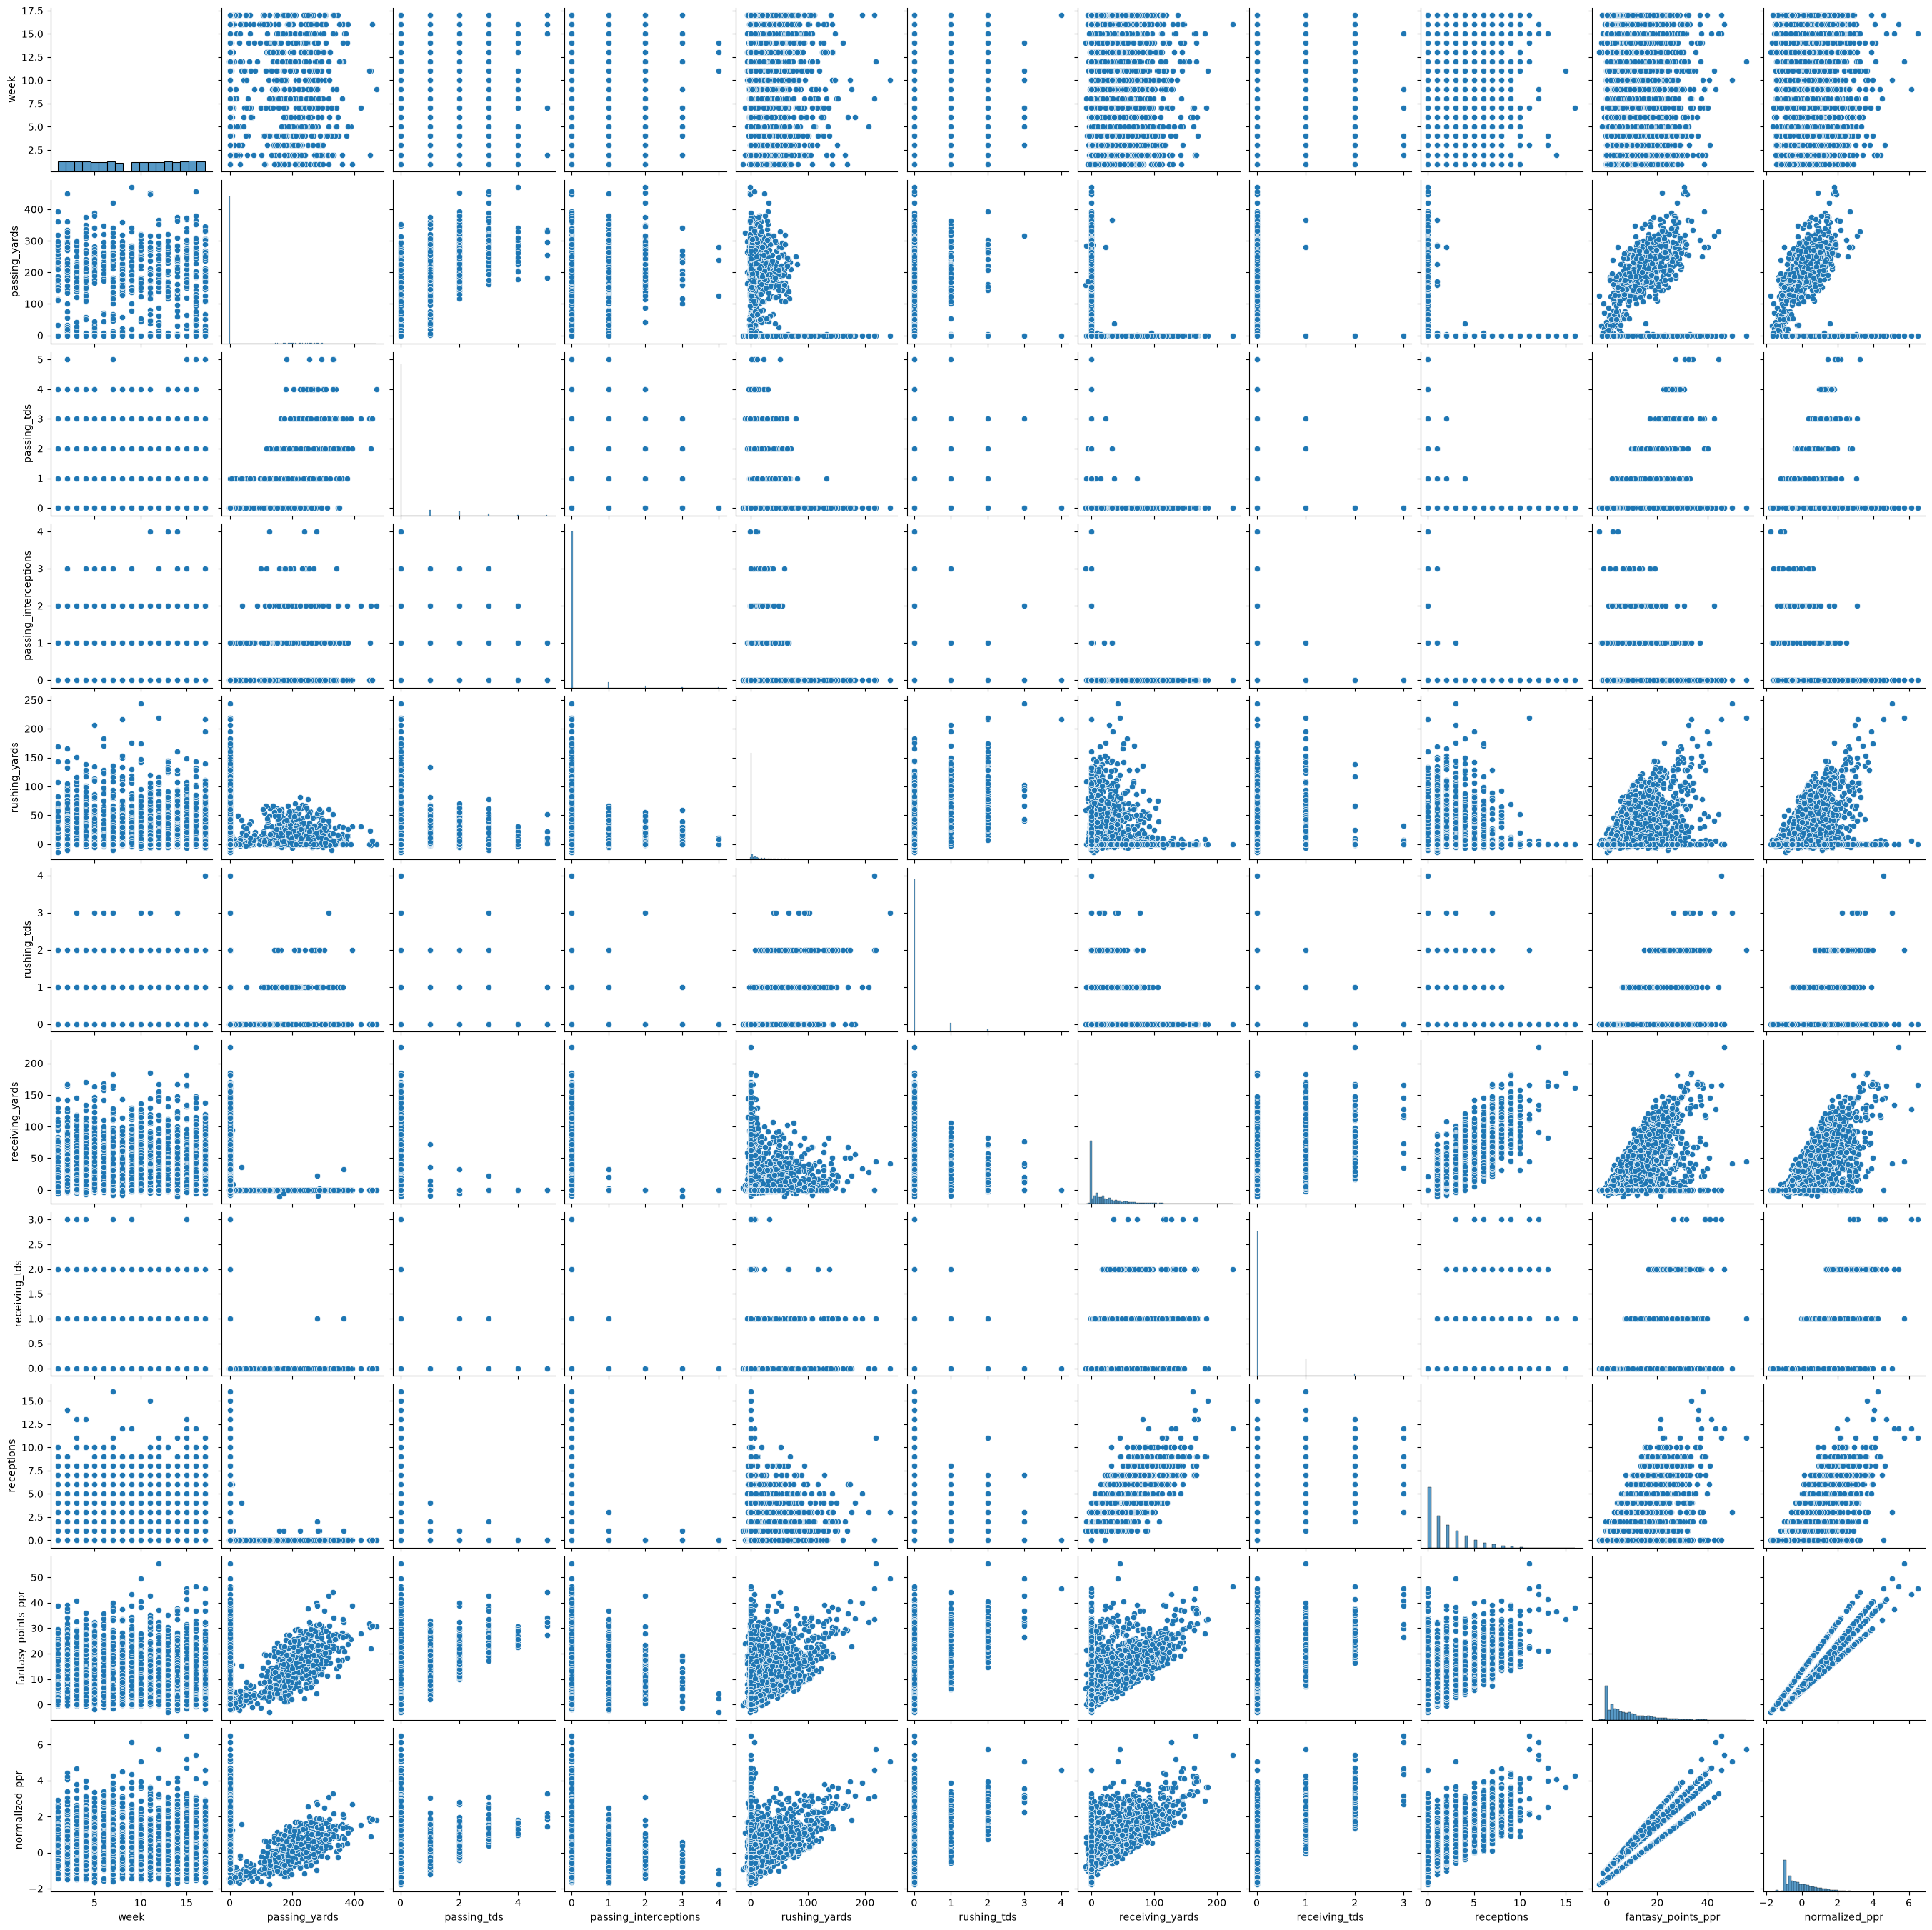

In [24]:
import seaborn as sns

fantasy_data = filtered_df.copy()

sns.pairplot(fantasy_data)

While this is really cool, it's probably too much information to include as a panel on my dashboard. I'll restrict the columns to only be those I really care about and their interactions with overall points.

One additional note on the plot, was confused as to what the distinct four diagonal lines were on the standard vs. normalized points. After inspecting realized it was the four different positions, which is a neat way to vizual how that data transformation worked.

Text(0.5, 1.1, 'Individual Statistics Affects on Fantasy Points')

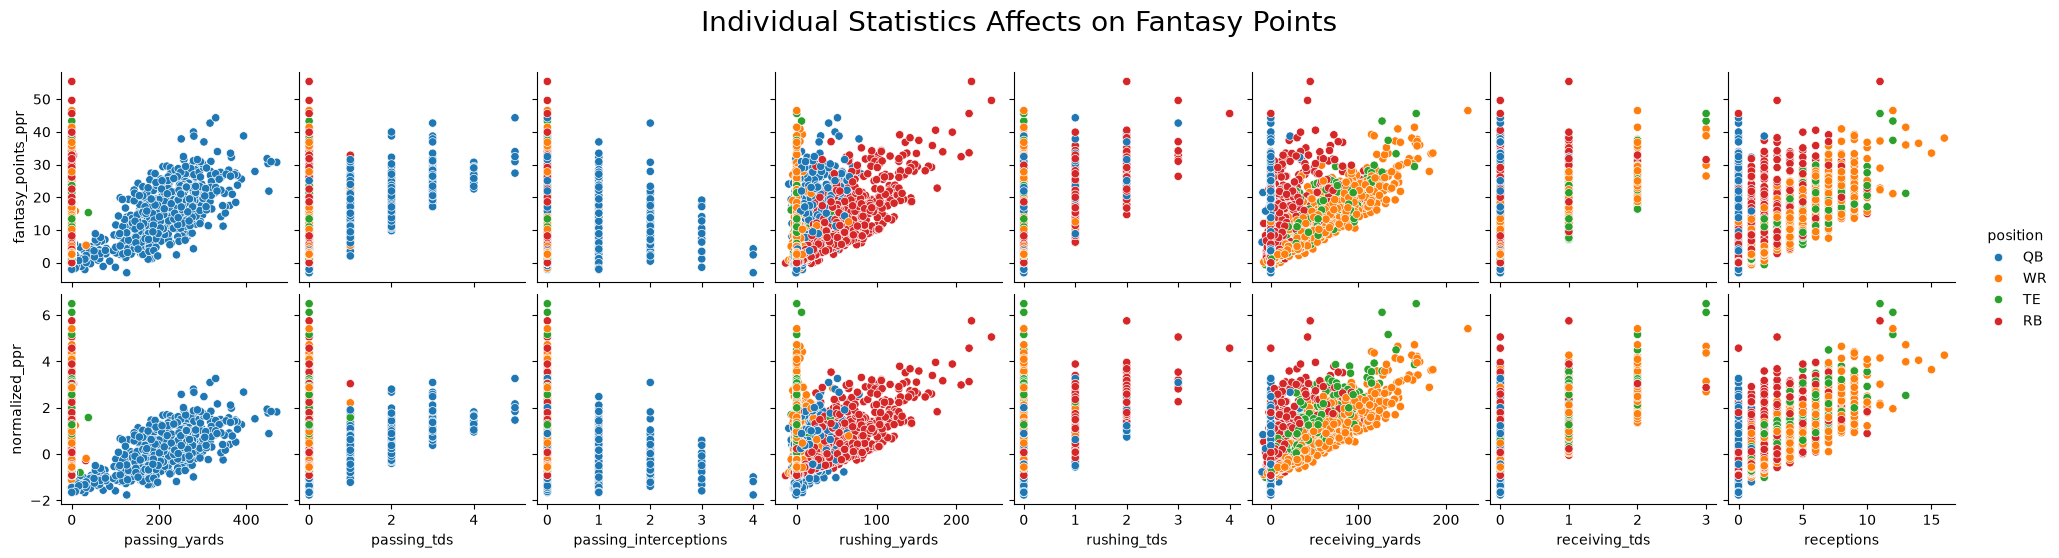

In [25]:
fantasy_data = filtered_df.copy()

matrices = sns.pairplot(data=fantasy_data,
             x_vars=['passing_yards', 'passing_tds', 'passing_interceptions',
                     'rushing_yards', 'rushing_tds', 'receiving_yards',	
                     'receiving_tds', 'receptions'],
            y_vars=['fantasy_points_ppr', 'normalized_ppr'],
            hue='position'
            )
matrices.figure.suptitle("Individual Statistics Affects on Fantasy Points", y = 1.1, fontsize = 20)

There are several interesting takeaways from this plot.
1. Quarterbacks don't seem to thrive when throwing no interceptions. A little risk appears to be good for the position from a scoring perspective.
2. Tightends appear to be heavily reliant on touchdowns, as the top relative performances appear to come from multiple touchdown games at a higher rate than other positions.
3. Wide recievers seem to be much less dependent on touchdowns than other positions.

**After Dashboard Creation:**

These takeaways can be a little difficult to see with the raw graph. Filtering the dashboard for position makes these trends much easier to view!

### Time Series

I want to see if certian positions get better as the season goes along, and if the region and weather of these teams affects this. To do this I'm going to create a time series of average raw points over time. Because this is an overall average, I won't need the normalized data for this plot.

<Axes: xlabel='week', ylabel='fantasy_points_ppr'>

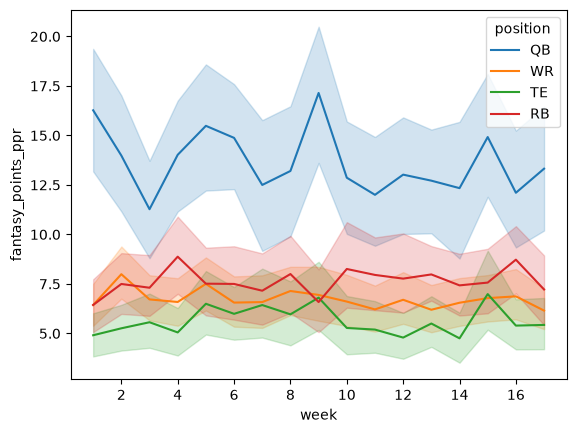

In [26]:
fantasy_data = filtered_df.copy()

sns.lineplot(data=fantasy_data,
             x='week',
             y='fantasy_points_ppr',
             hue='position')

My theory doesn't look correct so far. We'll have to see if toggling the divisions as a reactive value adds any additional insight into this data. I'll supplement this after adding that functionality.

**After Looking At Reactive Filters:**

While the performance over time did not shift in cold weather divisions (AFC North, NFC North), the difference between quarterbacks and every other position was significantly less than the NFL average. In the future, I'll prioritze position players from the north while staying away from their quarterbacks.

### TreeMap

I've investigated some overall trends that I think are interesting, but I really haven't answered the main question of this excercise. **WHO DO I DRAFT NEXT YEAR????**

To answer this, I want to add all players in a overall chart. My inspiration for this map are the famous S&P 500 treemaps that show stock performance by sector. I've linked an example below.

https://public.tableau.com/app/profile/dorian.barosan/viz/StockMarketOverview-NestedTreemap/StockMarketTreemap

In this example player position will be my sector, with total fantasy points controlling the size of the square. I'll start by including all players, but I may have to limit this to just the top portion if the squares get unreadable.

In [27]:
import plotly.express as px

fantasy_data = filtered_df.copy()

position_color_map = {"(?)": "lightgrey", "RB": '#d62728', 'QB': '#1f77b4', 'WR': '#ff7f0e', 'TE': '#2ca02c'}

season_data = (
    fantasy_data.groupby(['position', 'player_id', 'player_name'], as_index=False)
    .agg(
        normalized_ppr=('normalized_ppr', 'sum'),
        fantasy_points_ppr=('fantasy_points_ppr', 'sum')
    )
)

season_data = season_data[season_data['normalized_ppr'] > 0]

fig = px.treemap(
    season_data,
    path=[px.Constant('Total Points 2025 (normalized)'), 'position', 'player_name'], 
    values='normalized_ppr',
    color='position', 
    color_discrete_map=position_color_map,                                    
    color_discrete_sequence=px.colors.qualitative.Set2,   
    title='Total 2025 Season Points',
    hover_name = 'player_name',
    hover_data = ['fantasy_points_ppr']
)

fig.update_traces(
    hovertemplate=(
        '<b>%{label}</b><br>'
        'Raw Points: %{customdata[0]:.1f}<br>'
        'Normalized Points: %{value:.1f}<br>'
    ),
    root_color="lightgrey",
    insidetextfont=dict(color="white"),
    marker=dict(line=dict(width=2, color="grey"))
)

fig.show()

This is an awesome overall chart, a couple takeaways I have from this.
1. The theme of demphasizing quarterbacks continues, Josh Allen appears barely more impactful then the rest of the top 10 quarterbacks. This is particularly insightful as most leagues only have 10 teams, so there should be little scarcity to aquire a similar quarterback.
2. Trey Mcbride appears to be widely impactful compared to his position in a way no other player is. I will definetly be targetting him next season.
3. Runningback appears to be less deep than wide reciver, the boxes quickly shrink in impact as wide reciver tapers off more gradually.
4. I know from experience that wide recievers get hurt less frequently than runningbacks. Due to this, and their comporable relative values, I will be targeting this position heavily next year.

**Note:** AI was used in the generation of this plot. Prompts have been included in the AI log.

Now that I have my vizualizations, I can add them into an interactive dashboard.

## Dashboard

I was really impressed by the lecture on Panel dashboards. I would like to explore using this package for combining these vizualations into one hosted site.

In [28]:
%pip install panel jupyter_bokeh


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


**Note:** Generative AI was used to develop a Panel dashboard from the created visualizations. This has been included in the AI log.

### Setup Code:

In [29]:
import panel as pn
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

# Load Panel with Plotly support
pn.extension('plotly', sizing_mode='stretch_width')

In [30]:
# --- 1. Pre-calculate Full-Season Player Percentiles by Position ---
# Aggregate raw PPR points across all 17 weeks per player and position
player_season_totals = (
    filtered_df.groupby(['player_id', 'position'], as_index=False)['fantasy_points_ppr']
    .sum()
    .rename(columns={'fantasy_points_ppr': 'season_raw_ppr'})
)

# Compute 0-100 percentile within each position group
player_season_totals['pos_percentile'] = (
    player_season_totals.groupby('position')['season_raw_ppr']
    .rank(pct=True) * 100
)

# Merge the static percentile back into the weekly dataframe
dashboard_df = filtered_df.merge(
    player_season_totals[['player_id', 'position', 'pos_percentile']],
    on=['player_id', 'position'],
    how='left'
)

In [31]:
# --- 2. Define Interactive Filter Widgets ---
all_divisions = sorted(dashboard_df['division'].dropna().unique().tolist())
all_teams = sorted(dashboard_df['team'].dropna().unique().tolist())

division_filter = pn.widgets.MultiChoice(
    name='Divisions',
    options=all_divisions,
    value=all_divisions,
    placeholder='Select one or more divisions...'
)

team_filter = pn.widgets.MultiChoice(
    name='Teams',
    options=all_teams,
    value=all_teams,
    placeholder='Select one or more teams...'
)

week_slider = pn.widgets.IntRangeSlider(
    name='Weeks Included',
    start=int(dashboard_df['week'].min()),
    end=int(dashboard_df['week'].max()),
    value=(int(dashboard_df['week'].min()), int(dashboard_df['week'].max())),
    step=1
)

percentile_slider = pn.widgets.RangeSlider(
    name='Player Season Percentile (by Position)',
    start=0,
    end=100,
    value=(0, 100),
    step=1
)

# Helper function to filter the dataframe based on all 4 widgets
def get_filtered_data(divisions, teams, week_range, pct_range):
    if not divisions or not teams:
        return dashboard_df.iloc[0:0]  # Return empty DataFrame if nothing is selected
    
    mask = (
        dashboard_df['division'].isin(divisions) &
        dashboard_df['team'].isin(teams) &
        dashboard_df['week'].between(week_range[0], week_range[1]) &
        dashboard_df['pos_percentile'].between(pct_range[0], pct_range[1])
    )
    return dashboard_df[mask].copy()

In [38]:
# In[142]:
# --- 3. Reactive Plotting Functions (4 Visualizations) ---
POSITION_COLORS = {"RB": '#d62728', 'QB': '#1f77b4', 'WR': '#ff7f0e', 'TE': '#2ca02c'}

def _empty_plotly_fig(title_text):
    fig = go.Figure()
    fig.update_layout(
        title=title_text,
        template="simple_white",
        height=450,
        annotations=[dict(text="No data matches current filters", showarrow=False, font=dict(size=14))]
    )
    return fig

def _empty_mpl_fig(title_text):
    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.text(0.5, 0.5, "No data matches current filters", ha='center', va='center', fontsize=12)
    ax.set_title(title_text)
    ax.axis('off')
    plt.close(fig)
    return fig


# Plot 1: Weekly Top Scorers Lollipop Chart (Plotly)
def plot_lollipop(divisions, teams, week_range, pct_range):
    df = get_filtered_data(divisions, teams, week_range, pct_range)
    if df.empty:
        return _empty_plotly_fig("Weekly Top PPR Scorers")

    idx_max_raw = df.groupby('week')['fantasy_points_ppr'].idxmax()
    df_top_raw = df.loc[idx_max_raw].sort_values('week').reset_index(drop=True)

    idx_max_norm = df.groupby('week')['normalized_ppr'].idxmax()
    df_top_norm = df.loc[idx_max_norm].sort_values('week').reset_index(drop=True)

    fig = make_subplots(
        rows=2, cols=1,
        subplot_titles=("Weekly Top PPR Scorer", "Weekly Top Normalized Scorer"),
        vertical_spacing=0.25
    )

    def _add_lollipops(row_idx, target_df, val_col, val_label, is_norm=False):
        fmt = ":.2f" if is_norm else ":.1f"
        for pos in target_df['position'].unique():
            pos_df = target_df[target_df['position'] == pos]
            color = POSITION_COLORS.get(pos, '#333333')

            for _, row in pos_df.iterrows():
                fig.add_trace(
                    go.Scatter(
                        x=[row['week'], row['week']],
                        y=[0, row[val_col]],
                        mode='lines',
                        line=dict(color='lightgray', width=2),
                        showlegend=False,
                        hoverinfo='skip'
                    ),
                    row=row_idx, col=1
                )

            custom_data = list(zip(pos_df['player_name'], pos_df['position'], pos_df['team']))
            fig.add_trace(
                go.Scatter(
                    x=pos_df['week'],
                    y=pos_df[val_col],
                    mode='markers',
                    marker=dict(size=11, color=color),
                    name=pos,
                    legendgroup=pos,
                    showlegend=(row_idx == 1),
                    customdata=custom_data,
                    hovertemplate=(
                        "<b>Name:</b> %{customdata[0]} (%{customdata[2]})<br>"
                        f"<b>{val_label}:</b> %{{y{fmt}}}<br>"
                        "<b>Week:</b> %{x}<extra></extra>"
                    )
                ),
                row=row_idx, col=1
            )

    _add_lollipops(1, df_top_raw, 'fantasy_points_ppr', 'PPR Fantasy Points', is_norm=False)
    _add_lollipops(2, df_top_norm, 'normalized_ppr', 'Normalized Fantasy Points', is_norm=True)

    fig.update_layout(
        height=480,
        template="simple_white",
        title_text="<b>Weekly Top PPR Scorers</b>",
        margin=dict(l=40, r=20, t=60, b=40),
        legend=dict(title="<b>Position</b>", orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1)
    )
    fig.update_xaxes(title_text="Week", row=2, col=1)
    fig.update_yaxes(title_text="PPR Points", row=1, col=1, rangemode="tozero")
    fig.update_yaxes(title_text="Norm Points", row=2, col=1, rangemode="tozero")
    return fig


# Plot 2: Scatterplot Matrix (Seaborn PairGrid)
def plot_pairplot(divisions, teams, week_range, pct_range):
    df = get_filtered_data(divisions, teams, week_range, pct_range)
    if df.empty or df['position'].nunique() == 0:
        return _empty_mpl_fig("Individual Statistics Effects on Fantasy Points")

    g = sns.pairplot(
        data=df,
        x_vars=['fantasy_points_ppr', 'normalized_ppr'],
        y_vars=[
            'passing_yards', 'passing_tds', 'passing_interceptions',
            'rushing_yards', 'rushing_tds', 'receiving_yards',
            'receiving_tds', 'receptions'
        ],
        hue='position',
        palette=POSITION_COLORS,
        height=2.2,
        aspect=1.4,
        plot_kws={'alpha': 0.6, 's': 22}
    )
    g.figure.suptitle("Individual Statistics Effects on Fantasy Points", y=1.01, fontsize=13, fontweight='bold')
    
    # Move legend to top horizontal bar so it doesn't squeeze the 2 columns horizontally
    sns.move_legend(
        g, "upper center",
        bbox_to_anchor=(0.5, 0.995),
        ncol=4,
        title=None,
        frameon=False
    )
    g.figure.tight_layout(rect=[0, 0, 1, 0.97])
    
    fig = g.figure
    plt.close(fig)  # Prevent duplicate inline rendering in Jupyter
    return fig

# Plot 3: Average Points Time Series (Seaborn Lineplot)
def plot_timeseries(divisions, teams, week_range, pct_range):
    df = get_filtered_data(divisions, teams, week_range, pct_range)
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    
    if df.empty:
        ax.text(0.5, 0.5, "No data matches current filters", ha='center', va='center', fontsize=12)
        ax.axis('off')
        plt.close(fig)
        return fig

    sns.lineplot(
        data=df,
        x='week',
        y='fantasy_points_ppr',
        hue='position',
        palette=POSITION_COLORS,
        ax=ax
    )
    ax.set_title("Average Weekly Raw PPR Points by Position", fontsize=12, fontweight='bold')
    ax.set_xlabel("Week")
    ax.set_ylabel("Fantasy Points (PPR)")
    ax.legend(title="Position")
    sns.despine(ax=ax)
    fig.tight_layout()
    plt.close(fig)
    return fig

# Plot 4: Total Season Points Treemap (Plotly Express)
def plot_treemap(divisions, teams, week_range, pct_range):
    df = get_filtered_data(divisions, teams, week_range, pct_range)
    if df.empty:
        return _empty_plotly_fig("Total Season Points (Normalized)")

    season_data = (
        df.groupby(['position', 'player_id', 'player_name'], as_index=False)
        .agg(
            normalized_ppr=('normalized_ppr', 'sum'),
            fantasy_points_ppr=('fantasy_points_ppr', 'sum')
        )
    )
    season_data = season_data[season_data['normalized_ppr'] > 0]

    if season_data.empty:
        return _empty_plotly_fig("Total Season Points (Normalized — Positive Only)")

    treemap_colors = {"(?)": "lightgrey", **POSITION_COLORS}
    fig = px.treemap(
        season_data,
        path=[px.Constant('Selected Range Points (Normalized)'), 'position', 'player_name'],
        values='normalized_ppr',
        color='position',
        color_discrete_map=treemap_colors,
        title='<b>Total Season Points (Normalized)</b>',
        hover_name='player_name',
        hover_data=['fantasy_points_ppr']
    )

    fig.update_traces(
        hovertemplate=(
            '<b>%{label}</b><br>'
            'Raw Points: %{customdata[0]:.1f}<br>'
            'Normalized Points: %{value:.1f}<extra></extra>'
        ),
        root_color="lightgrey",
        insidetextfont=dict(color="white"),
        marker=dict(line=dict(width=1.5, color="grey"))
    )
    fig.update_layout(height=480, margin=dict(l=10, r=10, t=50, b=10))
    return fig

### Dashboard Layout Thoughts:

For the ordering of the charts, I wanted the player oriented plots to come first. Since the overall point of the dashboard is to identify who I want to draft, I wanted these vizualizaitons to capture the dashboard viewers attention first.

I think this grouping works well because a viewer can find a top player in the lollipop chart they're interested in and then look at their overall season in the treemap. This should hopefully make the exploration process smooth.

Additionally, I always like putting scrollable charts at the bottom of dashboard so they do not feel cramped in the overall layout. This worked out well with putting the scatterplot in the bottom right.

In [39]:
# In[143]:
# --- 4. Bind Widgets to Plots & Assemble 2x2 Dashboard ---
lollipop_pane = pn.pane.Plotly(
    pn.bind(plot_lollipop, division_filter, team_filter, week_slider, percentile_slider),
    sizing_mode='stretch_width'
)

pairplot_pane = pn.pane.Matplotlib(
    pn.bind(plot_pairplot, division_filter, team_filter, week_slider, percentile_slider),
    tight=True,
    sizing_mode='stretch_width'
)

timeseries_pane = pn.pane.Matplotlib(
    pn.bind(plot_timeseries, division_filter, team_filter, week_slider, percentile_slider),
    tight=True,
    sizing_mode='stretch_width'
)

treemap_pane = pn.pane.Plotly(
    pn.bind(plot_treemap, division_filter, team_filter, week_slider, percentile_slider),
    sizing_mode='stretch_width'
)

# Arrange the 4 visualizations in a 2x2 grid
grid_2x2 = pn.GridBox(
    pn.Card(lollipop_pane, title="1. Weekly Top Performers", collapsible=False),
    pn.Card(treemap_pane, title="2. Cumulative Positional Value", collapsible=False),
    pn.Card(timeseries_pane, title="3. Weekly Scoring Trends", collapsible=False),
    pn.Card(pn.Column(pairplot_pane, height=640, scroll=True),title="4. Stat-to-Point Relationships", collapsible=False),
    ncols=2,
    sizing_mode='stretch_width'
)

# Wrap in a clean template with filters in the sidebar
dashboard = pn.template.FastListTemplate(
    title="2025 Fantasy Football Exploration Dashboard",
    sidebar=[
        pn.pane.Markdown("### Dashboard Filters"),
        division_filter,
        team_filter,
        week_slider,
        percentile_slider,
    ],
    main=[grid_2x2],
    accent_base_color="#1f77b4",
    header_background="#1f77b4"
)

# Launch the dashboard on a local host server and open in browser
dashboard.show()

Launching server at http://localhost:51705


The main issue I had with this code was getting the scatterplot to display correctly. It started horizontally which I switched to vertical to help with spacing.

**Before Change:**

![Dashboard Screenshot](images/Before_Change.png)

**After Change:**

![Dashboard Screenshot](images/After_Change.png)


This is a good example of something I had to change from a generative AI output and has been included in the log.

### Pivot to Streamlit:

After doing some research, this link is not shareable with others. In order to provide access to the app itself, I have translated the dashboard into a streamlit app under "app.py" and hosted it on the github repository for this project.

I have attached the Streamlit link so you can check out the deployed version!

**Streamlit Link:** https://saids-521-app-apdsay3gdmhyahqrrum2te.streamlit.app/